# Семантические признаки музыкальных фрагментов: воспроизводимый baseline

**Александра Ивченко · тестовое «Разговорные рекомендации музыки по пользовательскому интенту»**

Один ноутбук покрывает задания 1–5: 80 реальных музыкальных фрагментов, извлечение признаков, EDA, три представления похожести и t-SNE.

**Границы результата.** Это анализ англоязычных человекописанных музыкальных описаний из MusicCaps, **не аудиоанализ**. Звук не загружался и не прослушивался. Настроение и контекст субъективны, контексты — слабые гипотезы. Метрики ниже не доказывают улучшение музыкальных рекомендаций.

**Воспроизведение:** в Colab выбрать Python 3 и «Выполнить всё». 80 исходных записей встроены; доступ к YouTube, ключи API и GPU не нужны. Результаты и графики появятся в `results/`.

**Помощь ИИ:** код и документация подготовлены с помощью Codex; использование LLM допускается условиями. Это следует раскрывать при защите, а не представлять работу как выполненную без помощи. Перед отправкой необходимо самостоятельно разобраться в коде и ограничениях.

In [1]:
import sys, importlib.util, subprocess
# В чистом Colab основные библиотеки обычно уже установлены.
needed = {'numpy': 'numpy', 'pandas': 'pandas', 'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib'}
missing = [package for module, package in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

import ast, json, re, hashlib, random, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from IPython.display import display, Markdown

SEED = 42
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__})

{'python': '3.12.14', 'numpy': '2.5.4', 'pandas': '2.2.3', 'sklearn': '1.9.1'}


## 1. Сбор и происхождение датасета

Источник: [Google / MusicCaps](https://huggingface.co/datasets/google/MusicCaps), файл `musiccaps-public.csv`, ревизия `0a51889`.
В исходной таблице — 5521 музыкальный фрагмент с описаниями и YouTube ID. Используем только текстовые аннотации и ссылки с временными границами. [Карточка данных](https://huggingface.co/datasets/google/MusicCaps/blob/0a51889/README.md).

**Отбор:** отсортировать genre-balanced subset по `ytid`, затем `random.Random(42).sample(..., 80)`. Отбор выполнен до анализа результатов извлечения, вручную примеры не подбирались. Подмножество сбалансировано авторами источника, но случайная выборка из него сама по себе не обязана иметь равные жанровые доли. Не ограничивали число треков на жанр; на ID видео — не более одного. Ограничить число на исполнителя нельзя: он отсутствует в исходных полях.

**Честная неполнота:** названия и исполнители не восстановлены. Вместо выдуманных названий используется `ytid` как идентификатор; поля `title` и `artist` пустые. В датасете есть не только студийные песни, но и музыкальные выступления и инструментальные отрывки. Доступность YouTube-ссылок не проверена; ссылка не означает, что видео ещё доступно.

**Лицензия:** исходные текстовые аннотации и производная разметка — [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/), источник Google / MusicCaps, описания сохранены, добавлены производные поля. Это не лицензия на аудиозаписи. Аудио не распространяется. См. Agostinelli et al., [MusicLM: Generating Music From Text](https://arxiv.org/abs/2301.11325), 2023.

In [2]:
SOURCE_SHA256 = '8cc109ac507b5e5aed8ea73a5c8f897a9d0793f7397427e000adf4c05f6021c7'
SOURCE_URL = 'https://huggingface.co/datasets/google/MusicCaps/resolve/0a51889/musiccaps-public.csv'
SOURCE_POOL_SIZE = 1000
SOURCE_ROWS = json.loads(r'''[{"ytid": "0fiOM---7QI", "start_s": 140, "end_s": 150, "audioset_positive_labels": "/m/04rlf,/m/06j64v", "aspect_list": "['traditional south asian music', 'old desi music', 'fast paced rhythmic singing', 'clapping hands', 'live performance', 'tabla playing', 'upbeat', 'vibrant']", "caption": "This is a traditional, cultural South Asian song. It is upbeat, vibrant, cheerful. The lead singer sings in a fast paced and rhythmic way, connecting many words within a short span of musical time. The rest of the performers are clapping their hands, playing the tabla. This is a live performance.", "author_id": 3, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "2dyEnOo3yJ8", "start_s": 330, "end_s": 340, "audioset_positive_labels": "/m/01c194,/m/04rlf,/m/06j64v", "aspect_list": "['low quality', 'traditional', 'mono', 'noisy', 'passionate female vocal', 'wooden percussive elements', 'flute melody', 'strings melody', 'passionate', 'emotional', 'soulful']", "caption": "The low quality recording features a traditional song that consists of passionate female vocal singing over wooden percussive elements, strings and flute melody. It sounds passionate, emotional and soulful and the recording is noisy and in mono.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "2xGRCsW6-Bk", "start_s": 100, "end_s": 110, "audioset_positive_labels": "/m/04rlf,/m/05r5wn", "aspect_list": "['low quality', 'champeta', 'wooden percussive elements', 'electric guitar solo melody', 'funky electric rhythm guitar chords', 'shimmering shakers', 'shimmering hi hats', 'smooth bass guitar', 'funky']", "caption": "The low quality recording features a Champeta song that consists of wooden percussive elements, electric guitar solo melody, funky electric rhythm guitar chords, shimmering shakers and hi hats and smooth bass guitar. It sounds funky and like something you would dance to in a bar.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "40D4L5Ndi6k", "start_s": 80, "end_s": 90, "audioset_positive_labels": "/m/03r5q_,/m/04rlf", "aspect_list": "['male singer', 'fast tempo', 'regional pop', 'folk pop', 'emphatic vocals', 'foreign language', 'bright violin', 'energetic', 'animated percussions', 'lively mandolin', 'acoustic guitar', 'groovy bass line', 'folk song', 'folk music', 'world music', 'pop', 'pop hits', 'youthful', 'dance music', 'celebration', 'merry', 'happy']", "caption": "A male vocalist sings this animated song in a foreign language. The tempo is fast with a bright applied violin accompaniment, lively drumming, groovy bass line, tambourine beats, rhythmic mandolin and acoustic guitar accompany net. The song is lively, energetic, vibrant, happy, vivacious and merry with a dance groove. This song is a Folk Pop/Regional Pop.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "4i11P4OCRfk", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/015vgc,/m/04rlf,/m/06j64v", "aspect_list": "['oriental', 'amateur recording', 'strings', 'dulcimer', 'tablas', 'slow to medium tempo']", "caption": "This recording contains a dulcimer playing a melody along with loud tablas playing a lot of deep hits that are overloading the recording speakers. At the end a string sound comes underlining with long pad notes. This song may be playing in a live event.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "8BJljuSm2Aw", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/t/dd00034", "aspect_list": "['ballad', 'plucked guitar', 'slow song', 'romantic song', 'male voice', 'slow tempo', 'minimal instruments', 'no percussion']", "caption": "This song is a ballad which features a male voice singing the main melody. This is accompanied by a plucked guitar playing arpeggiated chords. There are no other instruments. There is no percussion. The mood of this song is romantic. This song can be played in a romantic movie.", "author_id": 0, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "8zCZzzAaC4I", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/06j64v", "aspect_list": "['low quality recording', 'opera music', 'inspiring', 'emotional', 'uplifting', 'distorted recording', 'string instruments']", "caption": "This is an opera song that's recorded at a very low quality. The vocal audio is distorted and creates some fuzzy sounds, and the string instruments are muffled. The song is an uplifting, emotional song.", "author_id": 3, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "BWKQXn5xDwo", "start_s": 10, "end_s": 20, "audioset_positive_labels": "/m/04rlf,/m/07p78v5", "aspect_list": "['ballad/pop', 'acoustic piano', 'female singer', 'digital drums', 'amateur recording', 'uptempo', 'sad']", "caption": "An acoustic piano is playing a sad piece accompanied by a female singer. A simple digital drum with crash hits rounds up the composition. This song is an amateur recording but of decent quality. This song may be playing at  a talent show.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "CP3phqztym0", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/0gywn", "aspect_list": "['male vocalist', 'fast tempo', 'latin pop', 'latin song', 'banjo', 'spanish guitar', 'keyboard harmony', 'bright drumming', 'world music', 'regional music', 'happy', 'cheerful', 'enthusiastic', 'warm', 'sunny', 'upbeat', 'pleasant', 'funky bass lines', 'pandeireta', 'rhythmic acoustic guitar']", "caption": "A male vocalist sings this vivacious latin pop song. The tempo is fast with rhythmic Spanish guitar,keyboard harmony, bright drumming, mandolin harmony, groovy bass line and lively pandeira beats. The song is melodic, simple, happy, cheerful, bouncy, peppy , warm and joyful.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "D2w3qHmJrdU", "start_s": 0, "end_s": 10, "audioset_positive_labels": "/m/04rlf,/m/0dv5r", "aspect_list": "['instrumental music', 'cash register click', 'passionate', 'spirited', 'exciting', 'medium tempo', 'groovy rhythm', 'romantic', 'energetic', 'youthful', 'jazz music influences', 'dreamy', 'enterprising', 'guitar solo', 'groovy bass line', 'steady drumming rhythm', 'ad jingle', 'soundtrack', 'funk jazz music', 'shakers percussions', 'groovy', 'soul music', 'medium tempo']", "caption": "The song is an instrumental. The song is medium tempo with a guitar playing solo, steady drum rhythm, groovy bass line and steady bass line. The song is funky and groovy in nature. The song is an ad jingle.", "author_id": 1, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "DCFrCX4HPO8", "start_s": 120, "end_s": 130, "audioset_positive_labels": "/m/015lz1,/m/04rlf,/m/07pp8cl,/m/0glt670", "aspect_list": "['telephone ringing', 'hindi pop music', 'medium tempo', 'indian percussions', 'tambourine percussions', 'female singers', 'romantic', 'love song', 'hindi pop song', 'guitar rhythm', 'strong bass line', 'energetic', 'passionate', 'bollywood dance music', 'average audio quality', 'keyboard accompaniment']", "caption": "A female singer sings this passionate melody. The song is a medium  tempo with a groovy bass line , steady drumming, keyboard accompaniment, Indian percussion and tambourine accompaniment. The song is playful and romantic. The song is a modern Bollywood pop song with average quality audio.", "author_id": 1, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "DG5d4megH8g", "start_s": 180, "end_s": 190, "audioset_positive_labels": "/m/02p0sh1,/m/04rlf", "aspect_list": "['oriental', 'acoustic drums', 'strings', 'flute', \"percussion's\", 'medium to uptempo', 'amateur recording']", "caption": "An acoustic guitar is strumming chords. A violin is playing a melody along with a flue and another hammered string instrument. Percussions are being played in a rhythm that is not a 4 bar count. All the instruments are spread across the sides of the speakers. This song may be playing in a desert movie scene.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "DU5pD63Pv30", "start_s": 20, "end_s": 30, "audioset_positive_labels": "/m/04rlf,/m/07rrh0c", "aspect_list": "['advertisement', 'jingle', 'sound effects', 'bed creaking', 'laughter', 'accordion', 'goofy tune']", "caption": "These are sounds coming from an advertisement. There are sound effects of bed creaking and laughter implying an intercourse is taking place. Then the act is interrupted by a goofy accordion tune. Sounds from this track can be used in soundboards or in beat-making.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "EUNTykrvpok", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/02x8m,/m/04rlf,/m/06rqw,/m/0gywn", "aspect_list": "['low quality', 'vintage', 'northern soul', 'groovy bass', 'groovy piano melody', 'funky guitar chords', 'shimmering open hats', '4 on the floor kick', 'flat male vocal', 'melodic background male vocals', 'mono', 'warm', 'nostalgic', 'sentimental']", "caption": "The low quality recording features a northern soul song that consists of flat male vocals, alongside melodic male background vocals, singing over funky guitar chords, groovy piano chords, groovy bass, \"4 on the floor\" kick pattern and shimmering open hats. It is noisy and in mono and therefore vintage, but it also sounds warm, nostalgic and sentimental.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "FteW_2gNtD4", "start_s": 170, "end_s": 180, "audioset_positive_labels": "/m/04rlf,/m/05r5wn", "aspect_list": "['algerian folk music', 'rai', 'male vocal', 'chant-like singing', 'flute', 'percussion', 'vibrant', 'lively', 'energetic']", "caption": "This is an Algerian folk music, also known as Rai. There is a male vocalist singing in a chant-like manner. There is a flute playing the main melody while the rhythm is being provided by several percussive elements. There is a lively feel to it. This piece could be used in the opening shots of a movie taking place in North Africa. It could also be in the soundtrack of a desert-themed video game.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "H6qzijVEqZQ", "start_s": 10, "end_s": 20, "audioset_positive_labels": "/m/01jg1z,/m/04rlf", "aspect_list": "['pop funk', 'jingle', 'male vocal', 'melodic singing', 'electric guitar', 'bass guitar', 'acoustic drums', 'funky', 'easygoing', 'normal tempo', 'sound effects', 'breath', 'stamp', 'generic', 'easygoing']", "caption": "This is a pop funk piece used as a jingle for an ad. There is a male vocalist singing melodically while the electric guitar is playing a catchy tune with the bass guitar playing a groovy bass line. A normal tempo acoustic drum beat provides the rhythmic background. There are a couple of sound effects in the end. The piece has an easygoing atmosphere. It is the perfect match for a jingle. It could also be used in DJ sets or remixes.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "Ikdb_jA9ehU", "start_s": 0, "end_s": 10, "audioset_positive_labels": "/m/04rlf,/m/07qb_dv", "aspect_list": "['synth wave', 'dj scratching sound effect', 'groovy synth bass', 'wide simple bells melody', 'punchy snare', 'shimmering hi hats', 'soft crash cymbal', 'low quality', 'energetic', 'tinny percussive elements', 'punchy kick']", "caption": "The low quality recording features a DJ scratching effect at the beginning of the loop, after which a synth wave song drops. The song consists of groovy synth bass, percussive tinny elements, shimmering hi-hats, punchy snare and kick hits, soft crash cymbals and wide simple bells melody. It sounds energetic and judging by the arrangement, it's a background song for some kind of video.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "LB0u0PrlDHU", "start_s": 0, "end_s": 10, "audioset_positive_labels": "/m/026z9,/m/02x8m,/m/04rlf,/m/0ggx5q", "aspect_list": "['instrumental', 'electronic music', 'edm', 'punchy', 'trance', 'psychedelic', 'hypnotic', 'bouncy', 'thumping beat', 'buoyant', 'energetic', 'youthful', 'vigorous', 'dj', 'club music', 'dj mixer', 'drum machine', 'dance beats', 'dance groove', 'dance floor', 'pulsating', 'electric', 'percussive electronic music', 'club music', 'ambient', 'youthful']", "caption": "This music is an Electronic dance instrumental. The tempo is medium fast with punchy drum beats and groovy electronic arrangements.The music is buoyant, energetic, electric, pulsating, youthful and vigorous. The thumpy, rhythmic bass and drumming gives it a groovy dance beat.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "LRfVQsnaVQE", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/02p0sh1,/m/04rlf", "aspect_list": "['folk music', 'saxophone', 'hand claps', 'instrumental', 'no voices', 'tambourine', 'bass drum']", "caption": "This instrumental folk music features the main melody being played on a saxophone and a bowed instrument like a rebab. Both instruments play the same melody. This is accompanied by hand claps at every count of the bar. A bass drum is played on every count of the bar. A tambourine is playing a rhythmic beat. A bass is playing the same melody as the saxophone at a lower octave. There are no voices in this song. This song can be played at a celebration party.", "author_id": 0, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "OcdrbkDm2LQ", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/0l156b", "aspect_list": "['soul', 'low quality', 'instrumental', 'marimba melody', 'shimmering shakers', 'tinny metallic percussive elements', 'punchy kick', 'syncopate snare hits', 'low quality', 'mono', 'room microphone']", "caption": "The Soul Instrumental features an addictive marimba melody, shimmering shakers, punchy kick hits, syncopated snare and tinny metallic percussive elements. It sounds narrow because it is recorded with one mono room microphone and therefore it is a low quality recording.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "P25JeM4lPGw", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/015y_n,/m/04rlf,/m/0gywn", "aspect_list": "['low quality', 'flat female vocal', 'groovy snare', 'smooth double bass', 'groovy acoustic rhythm guitar', 'violins melody', 'live performance', 'groovy', 'folk/country', 'stereo microphone technique', 'uptempo', 'energetic']", "caption": "The low quality recording features a live performance of a folk/country song that consists of flat female vocal singing over smooth double bass, groovy acoustic rhythm guitar, violins melody and groovy snare rhythm. It sounds a bit noisy and roomy, as it was probably recorded with a stereo microphone technique, but also energetic, uptempo and groovy.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "ROM--1yVra8", "start_s": 180, "end_s": 190, "audioset_positive_labels": "/m/04rlf,/m/07p78v5", "aspect_list": "['pop music', 'medium-to-high pitch male vocal', 'melodic singing', 'electronic drums', 'strings', 'piano', 'bass', 'optimistic', 'passionate', 'emotional']", "caption": "This is a pop music piece. There is a medium-to-high pitch male vocal singing melodically in the lead. The melody is being played by the strings and the piano. There is a loud but simple electronic drum beat in the rhythmic background. The piece is in major key, so there is an optimistic aura. The piece could be used in the soundtracks of teenage dramas. It could also work well in an advertisement jingle.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "Rdwtr2IX8ek", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/02fxyj,/m/04rlf,/m/074ft", "aspect_list": "['loud vocal production', 'singer songwriter', 'gentle male vocals', 'acoustic guitar strumming', 'open chords', 'soft feel', 'folk rock', 'cafe', 'international']", "caption": "Soft singer songwriter folk rock with a gentle male vocal and acoustic guitar strumming. The vocal production is quite loud. Music for an international artsy cafe.", "author_id": 8, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "RneRJ5ZnHlE", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/0g293,/m/0ln16", "aspect_list": "['salsa music', 'upbeat', 'dance', 'fun', 'brass instruments', 'piano', 'bongo', 'conga', 'claves', 'charming female vocalist', 'energetic female vocalist']", "caption": "This is a salsa song with an upbeat and vibrant energy. It contains typical salsa instruments like the conga, the trumpet, and the piano. The percussion is upbeat and involves bongos and congas, and the singer is lively.", "author_id": 3, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "SG24NL2Xi3A", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/05rwpb,/m/06j6l,/m/074ft", "aspect_list": "['low quality', 'hip hop', 'arpeggiated piano melody', 'boomy kick', 'claps', 'soft crash cymbal', 'flat double male vocals', 'boomy bass', 'muddy', 'messy', 'bad mix', 'addictive']", "caption": "The low quality recording features a hip hop song sung with an addictive flow by flat double male vocals over arpeggiated piano melody, boomy, layered bass and kick hits, soft crash cymbal and claps. It sounds muddy and messy as the mix of the song is bad making the frequencies clash with each other - especially in the low end.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "Tsmx6Pb7CnU", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/026z9,/m/03mb9,/m/04rlf,/m/0ggx5q", "aspect_list": "['electro pop', 'buzzy sustained synth lead', '\"4 on the floor\" kick pattern', 'short reversed snare hit', 'claps', 'shimmering hi hats', 'groovy piano chords', 'sustained synth pad chord', 'energetic', 'arpeggiated synth melody']", "caption": "The Electro Pop song features a buzzy sustained synth lead, \"4 on the floor\" kick, short reversed snare hits, claps, shimmering hi hats, groovy piano chords, sustained synth pad chord and arpeggiated synth melody. It sounds energetic and like something you would hear in clubs.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "UrgzGbGVV8I", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/02sgy,/m/02v2lh,/m/04rlf,/m/06by7,/m/06w87,/m/0g12c5", "aspect_list": "['slow tempo', 'guitar lead', 'steady drumming rhythm', 'filler music', 'relaxing', 'home recording', 'chill-out music', 'modern pop', 'classic rock influences', 'amateur rock band', 'ambient music', 'groovy bass line', 'echo tones', 'relaxing', 'out of time', 'amateur playing', 'keyboard harmony', 'casual rock']", "caption": "The song is an instrumental music piece. The song is slow tempo with an electric guitar playing lead with heavy echoes, steady drumming and a keyboard harmony. The song is casual and slightly out of rhythm. The song is an instrumental  with a casual listening vibe.", "author_id": 1, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "VuWr1HXHoZg", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/01c194,/m/04rlf", "aspect_list": "['mantra', 'meditation music', 'male vocal', 'female vocal', 'chant', 'tambura', 'percussive elements', 'hypnotic', 'religious', 'immersive']", "caption": "This is a mantra/meditation music piece. There is a male and a female vocal chanting in a devotional manner. There is a tambura melody going on in the background while certain percussive elements at higher and lower ranges can be heard in the rhythmic structure. The atmosphere is hypnotic. This piece could be used in Hindu religious events.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "WT_wvvEvkw4", "start_s": 230, "end_s": 240, "audioset_positive_labels": "/m/028v0c,/m/04rlf,/m/07pxg6y", "aspect_list": "['outro', 'kids music', 'rain', 'thunder', 'male vocal', 'ocean sound effects']", "caption": "This is an outro for a kids song. The song features quirky male vocals. Right after the end of the phrase, thunderstorm sounds start to play in the background as well as ocean SFX.", "author_id": 5, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "WeDA1mDFSCo", "start_s": 60, "end_s": 70, "audioset_positive_labels": "/m/04rlf,/m/05rwpb,/m/06by7,/m/074ft,/m/0dl5d", "aspect_list": "['country rock', 'male voice', 'moderate tempo', 'bass guitar', 'electric guitar', 'simple percussion', 'romantic mood']", "caption": "This country rock song features a male voice singing at a high pitch. This is accompanied by percussion playing a simple beat. A guitar strums chords. The bass guitar plays the root notes of the chords. The mood of this song is romantic. This song can be played in a romantic movie.", "author_id": 0, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "YZx0_GRtvJk", "start_s": 250, "end_s": 260, "audioset_positive_labels": "/m/01z47d,/m/04rlf", "aspect_list": "['percussions', 'drum machine', 'boomy', 'catchy vocal riff', 'digital drumming', 'youthful', 'buoyant', 'punchy', 'bouncy', 'dance groove', 'amateur percussionist', 'male vocalist', 'slow tempo', 'pop rap', 'low audio quality', 'rap', 'hip-hop', 'beep', 'drum beats', 'rhythm arrangement']", "caption": "This song has a male vocalist singing a rhythmic vocal riff to the beat of digital drumming followed by the sound of a beep. The percussion is amateur and the vocals are muffled as the audio quality is inferior. The song is slow tempo and the beat is punchy, groovy, buoyant and youthful.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "aUXKK9AmrPU", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/07p78v5", "aspect_list": "['synthesizer sequence', 'resonant filter', 'techno', 'acid house', 'four on the floor kick', 'swung hi-hat', 'long reverb', 'syncopated synth bass', 'male singer', 'high chest voice', 'dark', 'sexy', 'big clap']", "caption": "A dark, sexy techno or acid house beat; with a repetitive synthesizer sequence with a squelchy resonant filter. The kick pattern is four on the floor with swung hi-hats and a syncopated synth bass. There is a big clap on the backbeat with a long reverb tail. The tempo is medium and the singer is male, singing in a high chest voice.", "author_id": 8, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "aY8-pXDdwiw", "start_s": 190, "end_s": 200, "audioset_positive_labels": "/m/02bk07,/m/04rlf", "aspect_list": "['choral harmony', 'slow tempo', 'viola harmony', 'sinister', 'mysterious', 'grim', 'grave', 'intense', 'spooky', 'acapella', 'chanting', 'threatening', 'low pitch', 'low notes', 'intense', 'grave', 'sound of viola', 'minimal instrumentation', 'intense bass lines', 'mellow', 'intense', 'dark']", "caption": "This song is a choral harmony. The tempo is slow with intense bass and an instrument that sounds like a viola. The song is grim, grave, intense, sinister; eerie; spooky; scary, chant-like, and dreary.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "ak7R0_8aKwI", "start_s": 40, "end_s": 50, "audioset_positive_labels": "/m/04rlf,/m/07xzm", "aspect_list": "['female singer', 'slow tempo', 'nursery rhyme', 'soothing', 'melodic', 'enchanting', 'chimes', 'xylophone', 'acoustic guitar', 'steady drumming', 'keyboard harmony', 'atmospheric synthesiser', 'soft', 'mellow', 'dreamy', 'lullaby', 'children’s song', 'kindergarten song', 'nostalgia']", "caption": "A female vocalist sings this soft melody. The tempo is slow with acoustic guitar rhythm, keyboard accompaniment, steady drumming , sound of chimes, xylophone, shakers and atmospheric synthesiser. The song is a sweet, dreamy, mellow, soothing ,lullaby for children.This song is a Nursery Rhyme.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "bTuKGXDrqdQ", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/02bxd,/m/04rlf", "aspect_list": "['live music', 'didgeridoo solo', 'aboriginal music', 'fusion music', 'inspiring', 'relaxing', 'male singer', 'raaga', 'vocalist chanting', 'poor audio quality', 'indian music influences', 'medium tempo', 'guitar accompaniment', 'folk music', 'poignant', 'spirited', 'ancient', 'meditational', 'love music', 'musical trio']", "caption": "The song is an instrumental with male vocalist chanting. The song is medium tempo with a didgeridoo playing percussively along with a guitar accompaniment. The song is meditative and has both aboriginal and Indian music influences . The audio quality is bad and it is a live audience performance.", "author_id": 1, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "bkYWnzw_5Bs", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/074ft,/t/dd00035", "aspect_list": "['r&b', 'cover', 'passionate female vocal', 'background harmonizing female vocals', 'punchy kick', 'claps', 'groovy bass', 'smooth synth keys', 'short strings chords', 'romantic', 'emotional', 'groovy', 'low quality']", "caption": "The low quality recording features a cover of a R&B song that contains passionate female vocals, alongside background harmonizing female vocals, singing over punchy kick, claps, groovy bass, smooth keys and short strings chords. It sounds romantic, emotional and groovy.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "cnvmLwFZr28", "start_s": 80, "end_s": 90, "audioset_positive_labels": "/m/015lz1,/m/04rlf,/m/05rwpb,/m/064t9,/m/074ft", "aspect_list": "['korean indie rock', 'alternative rock', 'male vocal', 'melodic singing', 'acoustic guitar', 'electric guitar', 'bass guitar', 'acoustic drums', 'gentle', 'mellow', 'easygoing', 'simple tune', 'slow tempo']", "caption": "This is a Korean indie rock piece. There is a male vocalist in the lead singing melodically. The main tune is being played by an acoustic guitar with an electric guitar and a bass guitar backing. There is a 4/4 slow tempo acoustic drum beat playing in the rhythmic background. The atmosphere is easygoing. This piece could be used in the soundtrack of a drama movie or TV series that takes place in Korea.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "cs-zcTX2tRA", "start_s": 170, "end_s": 180, "audioset_positive_labels": "/m/02mscn,/m/04rlf", "aspect_list": "['female child singer', 'poor audio quality', 'passionate', 'keyboard accompaniment', 'guitar rhythm', 'soaring vocals', 'pop hits', 'medium tempo', 'angelic', 'motivational', 'spirited', 'keybiard accompaniment', 'steady drumming rhythm', 'strong bass line', 'child prodigy', 'new age']", "caption": "A female child singer sings this soaring melody. The song is medium tempo with a steady drum rhythm, groovy bass line, piano accompaniment and keyboard harmony. The song is lilting and inspiring. The song is a pop song with poor audio quality.", "author_id": 1, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "f3l6KnC8930", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/07pkxdp", "aspect_list": "['pop', 'acoustic piano', 'female voice singing', 'sensual', 'string-section']", "caption": "A female voice is singing, sounding sensual while an acoustic piano is playing a ballad with a change in keys and strings being played with long strokes. The song sounds sensual and dramatic. You can hear some clicking sounds in the recording. This song may be played at a karaoke bar. This song seems to be an amateur recording.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "fH9CY48sfJY", "start_s": 330, "end_s": 340, "audioset_positive_labels": "/m/04rlf,/m/064t9,/m/0l15bq", "aspect_list": "['low quality', 'female vocals', 'clapping', 'crowd talking', 'noisy', 'compilation', 'weird', 'female vocal mumbling']", "caption": "The low quality recording features a compilation of a few different recordings that mostly consist of female vocals talking with each other and a loud crowd talking in the background. However, in the first section, there are also some claps and female vocals mumbling a song. The arrangement of the recordings is weird, but in context it probably makes sense.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "gXOyw8a4_Xs", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/015lz1,/m/01lyv,/m/04rlf,/m/07brj", "aspect_list": "['alternative/indi', 'keyboard', 'tambourine', 'congas', 'acoustic guitar', 'male higher voice singing', 'male backing vocals', 'medium tempo', 'amateur recording']", "caption": "Someone is strumming chords on an acoustic guitar singing along with a male voice in the higher register. male backing vocalists are supporting the singer. A piano is playing supportive chords along with congas and a tambourine. This is an amateur recording but of decent quality. This song may be playing live.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "hDsA_ky9Hfw", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/0145m,/m/04rlf,/m/0ggx5q,/t/dd00034", "aspect_list": "['electric guitar strumming', 'woodwind instrument', 'dance music', 'upbeat', 'groovy', 'soulful pop', 'classic soul', 'disco soul', 'raspy female vocal']", "caption": "The song is an upbeat, soulful song which has a motif repeated on a woodwind instrument. The song would be suitable for some mellow dancing. The singer has a raspy voice.", "author_id": 3, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "jqiD3VeM_hY", "start_s": 40, "end_s": 50, "audioset_positive_labels": "/m/0326g,/m/04rlf", "aspect_list": "['low quality', 'mixed background vocals', 'acoustic rhythm guitar', 'child talking', 'muffled', 'noisy', 'fun', 'happy']", "caption": "The low quality recording features a mixed background vocals singing over acoustic rhythm guitar. There is also a child talking over the song. The recording is noisy and muffled, but it sounds fun and happy.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "lHlOSsnP48c", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/07s8j8t,/m/07sbbz2", "aspect_list": "['rock', 'suspenseful electric guitar melody', 'punchy snare', 'simple kick pattern', 'groovy bass guitar', 'passionate male vocal', 'mono', 'low quality', 'energetic', 'uptempo', 'tinny percussive elements']", "caption": "The low quality recording features an uptempo rock song that consists of suspenseful electric guitar melody, punchy snare, simple kick pattern, groovy bass guitar, tinny percussive elements and passionate male vocal singing over it. The recording is in mono and it sounds energetic, groovy and like something you would dance to with your friends.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "liuCTk2nPG8", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/t/dd00032", "aspect_list": "['pop', 'disco', 'female vocals', 'electronic drums', 'percussion', 'keyboard', 'synth bass', 'dance', 'groovy', 'repeated theme']", "caption": "This is a famous disco piece. There are female vocals singing the lyrics joyfully. The main tune is played in major scale by a keyboard while it is supported by a syncopated synth bass in the background. The rhythm is kept by a repetitive electronic drum beat accompanied by percussion. The atmosphere is groovy and danceable. It is perfect for an 80s themed party setlist. It could also be playing in the background of an 80s themed bar.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "lwdDm3UO5WM", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/02p0sh1,/m/04rlf,/m/05lls,/m/0ggq0m", "aspect_list": "['live performance', 'traditional', 'passionate female vocal', 'subtle strings melody', 'relaxing', 'calming', 'low quality', 'reverberant']", "caption": "The low quality recording features a live performance of a traditional song and it consists of passionate female vocal singing over subtle strings melody. It is a bit reverberant as it was recorded in a larger room, but also relaxing and calming - like something you would meditate to.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "mMf4vJFT8Fw", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/018vs,/m/01glhc,/m/0342h,/m/04rlf,/m/0b_fwt,/m/0fx80y", "aspect_list": "['tuning', 'instructive', 'acoustic guitar sound', 'single note', 'sample', 'monotonous']", "caption": "This is an instructive track to tune a guitar at double drop D tuning. A repeated single note for each string is being played. This track could be used for unnatural sounding guitar samples.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "nBSMh7pgn2o", "start_s": 170, "end_s": 180, "audioset_positive_labels": "/m/04rlf,/t/dd00031", "aspect_list": "['pitched up male vocal', 'slow rock drum beat', 'sliding electric bass guitar', 'acoustic guitar', 'bongos', 'chipmunk', 'delay vocal']", "caption": "Chipmunk style pitched up male vocals over a slow rock drum beat, sliding electric bass guitar, acoustic guitar and bongos. Heavy use of delay on the vocal.", "author_id": 8, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "nZ5_UUUS8X8", "start_s": 70, "end_s": 80, "audioset_positive_labels": "/m/01b9nn,/m/01jnbd,/m/02rr_,/m/0342h,/m/04rlf,/m/0fx80y,/m/0g12c5", "aspect_list": "['electric guitar melody', 'huge reverb pedal effect', 'reverse pedal effect', 'noisy', 'low quality']", "caption": "The low quality recording features a person trying out the guitar effect pedal while playing some melodies on an electric guitar. There are huge reverb effects in the first part of the loop and reverse effects in the second part. It sounds a bit noisy too.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "nZmhIHZINL8", "start_s": 520, "end_s": 530, "audioset_positive_labels": "/m/02rr_,/m/0342h,/m/04rlf,/m/04szw,/m/07m2kt,/m/0fx80y,/t/dd00125", "aspect_list": "['low quality', 'arpeggiated electric guitar melody', 'pitch change', 'noisy', 'mono', 'passionate']", "caption": "The low quality recording features an arpeggiated electric guitar melody that changes pitch occasionally. The recording is very noisy and in mono, but it sounds passionate and like something John Lenon would sing to.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "ntfyeC178Tg", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/0dwt5", "aspect_list": "['low quality', 'boomy xylophone melody', 'fun', 'happy', 'muddy']", "caption": "The low quality recording features a boomy xylophone melody that gives off fun and happy vibes. Due to a huge amount of low frequencies, the recording sounds muddy as well.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "nvvXOfLs-ng", "start_s": 150, "end_s": 160, "audioset_positive_labels": "/m/04rlf,/m/07xzm,/m/0d8_n", "aspect_list": "['enka', 'low quality', 'mono', 'steel guitar solo melody', 'sustained strings melody', 'sustained brass melody', 'emotional', 'heartfelt', 'passionate', 'noisy', 'mellow bells chord progression']", "caption": "The low quality recording features an Enka song that consists of a steel guitar solo melody, mellow bell chord progression, sustained strings melody and sustained brass melody. The recording is noisy and in mono, and it sounds emotional, heartfelt and passionate.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "oXBGZoBYaLY", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/02bxd,/m/04rlf", "aspect_list": "['instrumental', 'medium tempo', 'oboe', 'woodwind', 'distant female vocals', 'waterfall', 'congas', 'bongos', 'oboist', 'congos', 'sound of waterfall', 'inferior quality sound recording', 'muddled recording', 'haunting sound', 'enigmatic sound', 'orchestral instrument']", "caption": "This song is an instrumental. The tempo is medium with the melody of an oboe and percussion rhythm like the bongos and the sound of a waterfall and faint female vocals in the background.the sound quality of the song is inferior and the sounds are distorted and muffled This song is an instrumental pop.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "ovVrS-q3Rzk", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/0145m,/m/01v1d8,/m/04rlf", "aspect_list": "['deck scratching', 'vinyl scratching', 'vocal manipulation', 'hip hop beat', 'mellow', 'dj skill', 'bright synth', 'simple hip hop drum beat']", "caption": "This is a clip containing vinyl or deck scratching. The DJ manipulates the deck back and forth to create scratching sound effects which have a melodic and percussive type of vibe. There's a mellow synth on which a simple progression is being played, and a simple hip hop drum beat is being played.", "author_id": 3, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "pWZqzEpygE0", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/06by7,/m/0dl5d,/m/0dls3", "aspect_list": "['rock&roll', 'acoustic drums', 'e-bass', 'e-guitar', 'male mid range singer', 'semi professional recording', 'medium to uptempo']", "caption": "Someone is playing acoustic drums with a half open hi hat holding a simple rock groove with snare hits as fill-ins. An e-bass plays a bassline along while an e-guitar is strumming slightly distorted chords. A male voice is singing in the mid-range. The whole recording sounds clean but is not a high professional recording. This song may be playing at a local festival.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "pzm90xLX9HM", "start_s": 450, "end_s": 460, "audioset_positive_labels": "/m/015vgc,/m/04rlf", "aspect_list": "['traditional', 'live performance', 'passionate male vocal', 'sustained accordion melody', 'low quality', 'tinny percussive elements', 'passionate background male vocal', 'noisy', 'mono', 'distorted', 'soulful']", "caption": "The low quality recording features a live performance of a traditional song and it consists of passionate male vocal, alongside passionate background male vocal singing over sustained accordion melody and some tinny percussive elements. Even though it is a bit distorted, mono and noisy, it still sounds soulful.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "qOTk01gmrRo", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/01hgjl,/m/04rlf", "aspect_list": "['dj', 'scratching', 'breakbeat', 'turntable', 'male vocal sample', 'electronic drums', 'strong bass', 'dance', 'groovy', 'urban']", "caption": "This is a breakbeat from a DJ set performance. The DJ is using the turntable to repeat the male vocal sample and add the scratching effect. In the background, the electronic drums and a strong bass are providing the rhythmic background at a medium tempo. It has a groovy, urban atmosphere. This performance could be used in a crime movie or a TV show with an urban ghetto setting.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "qlWEAm4AUTU", "start_s": 370, "end_s": 380, "audioset_positive_labels": "/m/026t6,/m/04rlf,/m/04szw,/m/07brj,/m/0l14md", "aspect_list": "['solo percussion instrument', 'tambourine', 'riq', 'pandeiro', 'steady beat', 'high cymbal', 'bongo', 'drum']", "caption": "Audio of a percussion instrument playing by itself. Sounds like a tambourine, riq, or pandeiro, playing a steady beat, alternating between a cymbal sound and a bongo drum sound.", "author_id": 8, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "rPAB0ymJGco", "start_s": 140, "end_s": 150, "audioset_positive_labels": "/m/04rlf,/m/07qqyl4", "aspect_list": "['heavy metal', 'sound effects', 'roar', 'dinosaur', 'distorted electric guitar', 'acoustic drums', 'loud', 'extreme', 'violent']", "caption": "This is a loud heavy metal piece that is played as a soundtrack for a video game with sound effects of fire and a dinosaur roaring in the beginning. There is a distorted electric guitar playing a simple tune while loud acoustic drums provide a heavy metal beat as the rhythmic background. The theme has a very violent feel to it.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "rWitVrXe5tg", "start_s": 40, "end_s": 50, "audioset_positive_labels": "/m/04rlf,/t/dd00033", "aspect_list": "['low quality', 'ambient classical', 'melancholic', 'sad', 'sustained string chords', 'slow arpeggiated guitar melody', 'smooth bass', 'emotional']", "caption": "The low quality recording features an ambient classical song that consists of sustained strings, chords, slow arpeggiated guitar melody and smooth bass. It sounds sad, melancholic and emotional.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "rfQ94EXIpTc", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/0326g,/m/04rlf", "aspect_list": "['instrumental', 'slow tempo', 'cello', 'whistling', 'resonator guitar', 'acoustic guitar', 'simple melody', 'people talking in background', 'busking', 'minimalist', 'soft', 'mellow', 'captivating', 'serene']", "caption": "This music is a pleasant instrumental. The music is slow tempo with a soft cello and guitar duet with a whistle melody. The song is mellow, soothing, calming , dulcet, warm and relaxing in contrast to the background noises of people talking and walking. The musicians are buskers.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "s1JHUf3Q_F0", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/0283d,/m/04rlf,/m/06cqb", "aspect_list": "['reggae song', 'male voice', 'vocal harmony', 'reggae drums', 'funky bass', 'moderate tempo', 'shaker', 'timbale', 'jam block']", "caption": "This reggae song features a male voice singing the main melody. Another voice is singing in harmony with the main voice. This is accompanied by reggae percussion. A timbale is played on every third count. Jam blocks are also played in the background. The bass plays a funky bassline with a reggae feel. Synth sounds are played in the background. This song can be played in a bar.", "author_id": 0, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "sOyHkcK_lOA", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/015lz1,/m/04rlf,/m/0g293,/m/0ln16", "aspect_list": "['male vocalist', 'medium tempo', 'latin song', 'super imposing background', 'mexican', 'cheering', 'dance music', 'latin dance music', 'dance hits', 'spanish', 'dance music', 'congas', 'bongos', 'trumpets', 'steady beat', 'salsa', 'bachata', 'people talking', 'clinking', 'tapping sound', 'scuffling', 'low audio quality', 'muddled audio']", "caption": "A male vocalist sings this peppy Latin pop song.the tempo is medium with animated trumpets, keyboard harmony and percussions rhythms of bongos, congas and subtle drums. The song is muffled and there are sounds in the background of people talking, cheering, the sound of clinking, scuffling and tapping. The song is super imposed by the background sounds. This song is a latin pop song.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "sZwZ2fOWWSg", "start_s": 130, "end_s": 140, "audioset_positive_labels": "/m/015lz1,/m/02w4v,/m/04rlf", "aspect_list": "['female singer', 'medium tempo', 'foreign language', 'regional pop', 'world music', 'tambourine', 'unique instrument', 'captivating', 'steady drumming', 'percussion instrument', 'simple bass lines', 'keyboard harmony', 'arabic music', 'middle eastern music']", "caption": "A female vocalist sings this captivating melody. The tempo is medium with enthusiastic drumming, soft keyboard harmony, steady bass lines and a middle eastern instrument. The song is rhythmic, catchy, peppy, vivacious and has a dance groove. This song is a Regional Pop song.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "sgwvhvkNELc", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/0164x2,/m/04rlf,/m/06cqb", "aspect_list": "['male singer', 'fast tempo', 'boomy bass lines', 'vibrant', 'enthusiastic', 'energetic', 'passionate', 'piano accompaniment', 'reggae', 'folk', 'jamaican folk', 'catchy vocal riff', 'keyboard harmony', 'repetitive rhythm', 'insistent', 'synthesiser arrangements', 'raspy vocals', 'upbeat', 'vibrant', 'enthusiastic', 'energetic', 'minimal instruments', 'electronic instruments', 'digital drum']", "caption": "A male vocalist sings this spirited song. The tempo is fast with keyboard harmony, piano accompaniment,groovy bass lines, digital drum and synthesiser arrangement. The song is catchy, enjoyable, youthful, energetic and vivacious with recurring and insistent rhythm and a dance groove. This song is a Reggae song.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "si_IAMPOXlQ", "start_s": 170, "end_s": 180, "audioset_positive_labels": "/m/011k_j,/m/04rlf", "aspect_list": "['instrumental', 'fast tempo', 'amplified piano', 'movie background score', 'hard hitting drums', 'ceremonial drums', 'bass drum', 'dissonant beats', 'violin harmony', 'ost', 'enthusiastic', 'intense']", "caption": "This music is an intense instrumental. The tempo is medium with hard hitting drums, ceremonial big drums, amplified piano and violin harmony. The music is syncopated and intense. It is like a background score for a movie.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "tRA-5inwlMI", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/07brj,/m/0ln16", "aspect_list": "['tambourine dance', 'gospel', 'electric guitar', 'xylophone', 'female vocal', 'religious', 'christian', 'church']", "caption": "This is a gospel piece used as an accompaniment to a tambourine dance. There is a female vocalist singing. There is an electric guitar and a xylophone playing the melody. The tune is not very clear due to the quality of the recording. The atmosphere is religious. Samples could be lifted from this recording to be used in a beat.", "author_id": 9, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "tWseBEYhE1M", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/0h9mv", "aspect_list": "[\"children's music\", 'twinkling sounds', 'truck sounds', 'keyboard song', 'no voices', 'programmed percussion', 'moderate tempo', 'happy feel']", "caption": "This children's song features truck sounds. This is accompanied by a keyboard playing a melody using a flute-like sound. A twinkling melody is played in the background. The percussion is programmed. The percussion plays a simple beat. The bass plays the root and fifth notes of the chords. The mood of the song is happy. There are no voices in this song. This song can be used in a children's animated movie.", "author_id": 0, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "v2Ng8iGwf40", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/07pbtc8,/m/07qdb04", "aspect_list": "['game music', 'quirky sounds', 'bassline', 'waterfall sounds', 'no lyrics', 'bird sounds', 'simple percussion', 'moderate tempo', 'violins', 'bubble sounds', 'xylophone sound']", "caption": "This song features sounds from a game. A groovy bassline is played. This is accompanied by percussion playing a simple rhythm. A violin fill is played in the background. Quirky sounds are played in the foreground depicting some actions like jumping and crossing game levels. Birds can be heard chirping in the background. There is the sound of a waterfall toward the end of the clip. Bubble bursting sounds are played when the character collects some rewards. There are no lyrics in this song and no words being sung.", "author_id": 0, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "v582kPp43Mg", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/011k_j,/m/04rlf", "aspect_list": "['marching band', 'patriotic song', 'male voices', 'orchestral music', 'moderate tempo', 'happy mood', 'victorious feel']", "caption": "This orchestral song features male voices singing the main melody. The song starts off with a marching beat played on snare drums. When the voices start to sing, the feeling is one of victory. This is accompanied by percussion playing a marching beat. There are instruments playing staccato notes. The bass is played on a stringed instrument and it follows the root notes of the chords. This song is played at a moderate tempo. This is a patriotic song.", "author_id": 0, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "v6A7Iggebm4", "start_s": 180, "end_s": 190, "audioset_positive_labels": "/m/015lz1,/m/0342h,/m/04rlf,/m/0fx80y,/t/dd00004", "aspect_list": "['low quality', 'noisy', 'shimmering shaker', 'reverberant', 'passionate female vocal', 'cover', 'acoustic rhythm guitar chords progression', 'rock', 'happy', 'fun']", "caption": "The low quality recording features a cover of a rock song sung by passionate female vocalists, followed by acoustic rhythm guitar chord progression and shimmering shaker. It is a bit reverberant and noisy, as they are playing in a room. It gives off happy and fun vibes.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "vrMmkVV4SOE", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/07rwj3x", "aspect_list": "['funk/disco', 'acoustic drums', 'organ', 'amateur recording', 'medium tempo']", "caption": "An organ is playing low notes serving as a bassline while a drummer is hitting the drums with a lot of fill-ins losing the rhythm and shouting. This recording is of poor quality.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "wKoFJHb2BoI", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/018vs,/m/02sgy,/m/0342h,/m/04rlf,/m/04szw,/m/0fx80y", "aspect_list": "['soul/ballad', 'backing track', 'e-guitar', 'slow tempo', 'sensual']", "caption": "Someone is playing a solo on a clean e-guitar along with a backing track that sounds like a slow soulful, sad ballad with strings,bass, acoustic drums and an e-guitar strumming single chords as a rhythmic instrument. This song may be played outside by a busker.", "author_id": 6, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "whZygh228yw", "start_s": 150, "end_s": 160, "audioset_positive_labels": "/m/02cjck,/m/04rlf", "aspect_list": "['western classical music', 'tense', 'ominous', 'utmost importance', 'life changing moments', 'eerie', 'spirited', 'passionate', 'opera hall', 'creating fear', 'timpani percussions', 'drums playing furiously', 'string section', 'conductor', 'composer', 'horn section', 'brass section', 'emotional', 'scary', 'building anticipation', 'philharmonic orchestra']", "caption": "The song is an instrumental piece. The song is medium tempo with a furiously playing timpani percussion, string section playing, horns playing and low pitched harmony that evokes danger and suspense. The song is a modern western classical instrumental.", "author_id": 1, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "x1x54MgStxQ", "start_s": 130, "end_s": 140, "audioset_positive_labels": "/m/04rlf,/m/04szw,/m/07xzm,/m/0fx80y,/m/0l14_3", "aspect_list": "['male singer', 'indian music', 'ukulele accompaniment', 'bengali pop song', 'emotional', 'spirited', 'message of kindness', 'passionate', 'love anthem', 'madly in love', 'adore you', 'medium tempo', 'groovy music', 'tambourine percussion', 'steady drumming rhythm', 'clapping rhythm', 'groovy bass line', 'indian pop song', 'private music video']", "caption": "A male singer sings this delightful melody. The song is medium tempo with a ukulele accompaniment, steady drumming rhythm with various percussions like clapping and tambourine along with a keyboard accompaniment. The song is emotional and groovy. The song is a local Indian language pop song, most probably a Bengali pop song.", "author_id": 1, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "xb07gLlmkL8", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/01v1d8,/m/04rlf,/m/0l14qv", "aspect_list": "['instrumental', 'medium tempo', 'indie rock', 'experimental', 'meditative', 'pensive', 'grimelectronic music', 'atmospheric synthesiser', 'surround sound', 'intense', 'psychedelic', 'trippy', 'halluciatory', 'trance music', 'keyboard harmony', 'subtle bass', 'rock', 'alternative rock', 'synth pop', 'indie roc', 'progressive rock']", "caption": "This music is instrumental. The tempo is medium with atmospheric synthesiser, soft keyboard harmony and subtle bass lines in the background. The music is progressive with a lot of digital sounds giving it a psychedelic,meditative, trippy, trance like vibe. This instrumental is Synth Rock/Progressive Rock.", "author_id": 7, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "xtGmrLOsjHk", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/05lls", "aspect_list": "['low quality', 'muffled strings section', 'muffled passionate female opera singer', 'noisy', 'mono', 'emotional', 'vintage', 'warm']", "caption": "The low quality recording contains a muffled strings section and a muffled passionate female opera singer, singing over it. The recording is noisy and in mono, and judging by the tone of it, old - which makes it vintage. It sounds emotional, warm and passionate.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "yVWk3yq3Abc", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/01jnbd,/m/04rlf,/m/06cqb", "aspect_list": "['reggae', 'low quality', 'wide harmonizing low male vocals', 'offbeat piano chords', 'groovy bass', 'muffled snare', 'tinny percussive elements', 'shimmering hi hats', 'noisy', 'easygoing', 'chill']", "caption": "The low quality recording features a reggae song that consists of wide harmonizing low male vocals singing over groovy bass, muffled snare, shimmering hi hats, tinny percussive elements and offbeat piano chords. The recording is noisy and it sounds easygoing and chill.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "zU4mwg-HHoQ", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/04rlf,/m/05lls", "aspect_list": "['live performance', 'low quality', 'opera', 'passionate female vocal', 'groovy piano melody', 'noisy', 'reverberant']", "caption": "The low quality recording features opera live performance that consists of passionate female vocal singing over groovy piano melody. The recording is very noisy, in mono and very reverberant as it was probably recorded in a medium size hall, with a poor quality microphone.", "author_id": 4, "is_balanced_subset": true, "is_audioset_eval": true}, {"ytid": "ztfegVzqeCI", "start_s": 30, "end_s": 40, "audioset_positive_labels": "/m/015lz1,/m/01v1d8,/m/04rlf,/m/07kc_,/m/0l14qv", "aspect_list": "['female singer', 'synth bass', 'reverb', 'theremin', 'unconventional', 'retro', 'sci-fi', 'quirky drum machine', 'wide aggressive vibrato', 'wild']", "caption": "A quirky drum machine and warm synth bass provide the accompaniment for a female singer with noticeable reverb. A wild theremin with delay and wide aggressive vibrato enters to give the music a wild sci-fi feel.", "author_id": 8, "is_balanced_subset": true, "is_audioset_eval": true}]''')

tracks = pd.DataFrame(SOURCE_ROWS)
tracks['track_id'] = tracks['ytid']
tracks['title'] = None
tracks['artist'] = None
tracks['audio_url'] = tracks.apply(lambda r: f"https://www.youtube.com/watch?v={r.ytid}&t={r.start_s}s", axis=1)
tracks['audio_link_status'] = 'not_checked'
tracks['source'] = 'google/MusicCaps@0a51889'
assert 50 <= len(tracks) <= 100
assert tracks.track_id.is_unique
assert (tracks.end_s - tracks.start_s).eq(10).all()
assert tracks.caption.str.strip().ne('').all()
assert tracks.ytid.str.fullmatch(r'[A-Za-z0-9_-]{11}').all()
print('Source pool:', SOURCE_POOL_SIZE, '| Selected:', len(tracks), '| Source SHA256:', SOURCE_SHA256)
display(tracks[['track_id','audio_url','start_s','end_s','title','artist','caption']].head(5))

Source pool: 1000 | Selected: 80 | Source SHA256: 8cc109ac507b5e5aed8ea73a5c8f897a9d0793f7397427e000adf4c05f6021c7


,track_id,audio_url,start_s,end_s,title,artist,caption
0,0fiOM---7QI,https://www.youtube.com/watch?v=0fiOM---7QI&t=...,140,150,None,None,"This is a traditional, cultural South Asian so..."
1,2dyEnOo3yJ8,https://www.youtube.com/watch?v=2dyEnOo3yJ8&t=...,330,340,None,None,The low quality recording features a tradition...
2,2xGRCsW6-Bk,https://www.youtube.com/watch?v=2xGRCsW6-Bk&t=...,100,110,None,None,The low quality recording features a Champeta ...
3,40D4L5Ndi6k,https://www.youtube.com/watch?v=40D4L5Ndi6k&t=80s,80,90,None,None,A male vocalist sings this animated song in a ...
4,4i11P4OCRfk,https://www.youtube.com/watch?v=4i11P4OCRfk&t=30s,30,40,None,None,This recording contains a dulcimer playing a m...


### Как повторить отбор из исходного файла (необязательная сетевая проверка)

Для воспроизводимого запуска достаточно встроенных записей. Сетевая проверка выключена по умолчанию. При включении скачивает только CSV и проверяет его SHA256; не загружает аудио.

In [3]:
VERIFY_SOURCE_ONLINE = False
if VERIFY_SOURCE_ONLINE:
    import urllib.request, io
    raw = urllib.request.urlopen(SOURCE_URL, timeout=45).read()
    assert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256, 'Source has changed'
    source_df = pd.read_csv(io.BytesIO(raw))
    mask = source_df.is_balanced_subset.astype(str).str.lower().eq('true')
    ids = sorted(source_df.loc[mask, 'ytid'])
    selected = sorted(random.Random(SEED).sample(ids, 80))
    assert selected == sorted(tracks.ytid.tolist())
    print('Source checksum and all 80 IDs verified')
else:
    print('Offline mode: embedded source rows; remote availability not checked.')

Offline mode: embedded source rows; remote availability not checked.


## 2. Набор признаков и полезность

| Семейство | Примеры | Для чего полезно | Ограничение |
|---|---|---|---|
| Жанр, multilabel | rock, jazz, classical | сужение кандидатов, объяснение | только явные слова, нет полного таксономического дерева |
| Настроение, multilabel | calm, happy, sad, energetic | запросы про состояние и атмосферу | субъективно, возможны несколько меток |
| Темп и энергия | slow/medium/fast, low/high | тренировка, спокойная музыка | словесные признаки, **не измеренный BPM** |
| Вокал и инструменты | instrumental, vocal; piano, guitar | «без слов», сходство звучания | отсутствие упоминания не означает отсутствие инструмента |
| Контекст, multilabel | relaxation, focus, workout, party | сопоставление с пользовательским намерением | слабые правила; не подтверждённая пригодность |

Не предсказываем эпоху, исполнителя и «похожих артистов» из недостаточных данных. Нет уверенных свидетельств — неизвестное значение или пустой список. Атмосфера представлена настроением, а не дополнительным дублирующим тегом.

## 3. Пайплайн извлечения

**Вход модели — только `caption`.** `aspect_list` сохранён отдельно для слабой диагностической проверки в разделе 5 и не включён в представление треков. Не обучаем классификатор на этих 80 примерах.

Выбран прозрачный словарный NLP-baseline: поиск слов и фраз с границами, простые отрицания, сохранение найденных свидетельств, обработка противоречий. Он воспроизводим без внешних сервисов и легко проверяется. Стоимость — пропуск синонимов и сложных конструкций.

Альтернативы: LLM с JSON-схемой лучше понимает контекст, но требует оценки галлюцинаций и затрат; CLAP позволяет сравнивать аудио с текстом, но требует доступных аудиофрагментов и загрузки модели; обученный классификатор требует разметки и разделения данных. Эти модели здесь **не запускались**. Следующий разумный шаг — аудио/text embedding baseline на доступном для прослушивания корпусе с независимой оценкой.

In [4]:
GENRES = {
    'rock': ['rock', 'rock and roll', 'rock n roll'], 'pop': ['pop'],
    'jazz': ['jazz', 'jazzy'], 'classical': ['classical', 'orchestral', 'symphony'],
    'electronic': ['electronic', 'techno', 'edm', 'house music', 'trance', 'dubstep'],
    'hiphop': ['hip hop', 'hiphop', 'rap', 'rapping'],
    'folk_country': ['folk', 'country'], 'blues': ['blues', 'bluesy'],
    'metal': ['metal', 'heavy metal'], 'reggae': ['reggae', 'reggaeton'],
    'soul_funk': ['soul', 'soulful', 'funk', 'funky', 'r&b', 'rnb'],
    'ambient': ['ambient']}
MOODS = {
    'calm': ['calm', 'relaxing', 'relaxed', 'soothing', 'peaceful', 'mellow', 'meditative'],
    'happy': ['happy', 'joyful', 'cheerful', 'uplifting', 'playful'],
    'sad': ['sad', 'melancholic', 'melancholy', 'sorrowful'],
    'energetic': ['energetic', 'energetic feel', 'upbeat', 'exciting', 'lively'],
    'tense': ['tense', 'aggressive', 'dark', 'dramatic', 'intense']}
TEMPOS = {'slow': ['slow', 'slow tempo', 'slow paced'],
          'medium': ['medium tempo', 'mid tempo', 'moderate tempo'],
          'fast': ['fast', 'fast paced', 'fast tempo', 'uptempo']}
ENERGY = {'low': ['soft', 'gentle', 'mellow', 'calm', 'relaxing'],
          'high': ['energetic', 'powerful', 'aggressive', 'upbeat', 'intense', 'loud']}
INSTRUMENTS = {'piano': ['piano'], 'guitar': ['guitar'], 'drums': ['drums', 'percussion'],
               'bass': ['bass', 'e bass'], 'strings': ['violin', 'cello', 'strings'],
               'synth': ['synth', 'synthesizer', 'synthesizers'],
               'wind': ['flute', 'saxophone', 'trumpet', 'clarinet']}


def clean_text(text):
    if not isinstance(text, str):
        return ''
    return re.sub(r'\s+', ' ', text.lower().replace('-', ' ')).strip()


def phrase_hits(text, phrases, allow_negated=False):
    """Limited window negation is intentional; evidence is a text fragment, not a probability."""
    text = clean_text(text)
    found = []
    for phrase in phrases:
        pattern = r'(?<!\w)' + re.escape(phrase) + r'(?!\w)'
        for match in re.finditer(pattern, text):
            before = text[max(0, match.start()-35):match.start()]
            # Last three words, scoped to the current simple clause.
            before = re.split(r'[.,;:!?]', before)[-1]
            words = before.split()[-3:]
            negated = any(w in {'no','not','without','never'} for w in words)
            if allow_negated or not negated:
                found.append({'term': phrase, 'snippet': text[max(0,match.start()-22):match.end()+30]})
    return found


def dictionary_labels(text, vocabulary):
    evidence = {label: phrase_hits(text, terms) for label, terms in vocabulary.items()}
    return sorted(label for label, hits in evidence.items() if hits), {k:v for k,v in evidence.items() if v}


def extract_features(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError('Expected a non-empty English caption')
    genres, ge = dictionary_labels(text, GENRES)
    moods, me = dictionary_labels(text, MOODS)
    tempos, te = dictionary_labels(text, TEMPOS)
    energies, ee = dictionary_labels(text, ENERGY)
    instruments, ie = dictionary_labels(text, INSTRUMENTS)
    instr = phrase_hits(text, ['instrumental', 'no vocals', 'no voices', 'no voice', 'no singing', 'without vocals'], True)
    voc = phrase_hits(text, ['singing', 'sings', 'singer', 'vocalist', 'vocal', 'vocals', 'rapping', 'rapper', 'voice', 'voices'])
    vocal = 'mixed_or_conflicting' if instr and voc else ('instrumental' if instr else ('vocal' if voc else 'unknown'))
    # Conflict is preserved rather than selecting an arbitrary tempo/energy.
    tempo = tempos[0] if len(tempos)==1 else ('mixed_or_conflicting' if tempos else 'unknown')
    energy = energies[0] if len(energies)==1 else ('mixed_or_conflicting' if energies else 'unknown')
    contexts, ce = [], {}
    if 'calm' in moods:
        contexts.append('relaxation'); ce['relaxation'] = 'calm mood -> weak hypothesis'
    if 'calm' in moods and vocal == 'instrumental':
        contexts.append('focus'); ce['focus'] = 'calm + instrumental -> weak hypothesis'
    if energy == 'high' and tempo == 'fast':
        contexts.append('workout'); ce['workout'] = 'high energy + fast tempo -> weak hypothesis'
    party = phrase_hits(text, ['party', 'dance', 'dancing', 'club'])
    if party:
        contexts.append('party'); ce['party'] = party
    return {'genres': genres, 'moods': moods, 'tempo': tempo, 'energy': energy,
            'vocal': vocal, 'instruments': instruments, 'contexts': sorted(contexts),
            'evidence': {'genres':ge, 'moods':me, 'tempo':te, 'energy':ee,
                         'vocal':{'instrumental':instr,'vocal':voc}, 'instruments':ie, 'contexts':ce}}

features = tracks.caption.apply(extract_features).apply(pd.Series)
enriched = pd.concat([tracks, features], axis=1)
display(enriched[['track_id','genres','moods','tempo','energy','vocal','contexts']].head(10))
display(enriched[['track_id','caption','evidence']].head(2))

,track_id,genres,moods,tempo,energy,vocal,contexts
0,0fiOM---7QI,[],"[energetic, happy]",fast,high,vocal,[workout]
1,2dyEnOo3yJ8,[soul_funk],[],unknown,unknown,vocal,[]
2,2xGRCsW6-Bk,[soul_funk],[],unknown,unknown,unknown,[party]
3,40D4L5Ndi6k,"[folk_country, pop]","[energetic, happy]",fast,high,vocal,"[party, workout]"
4,4i11P4OCRfk,[],[],unknown,high,unknown,[]
5,8BJljuSm2Aw,[],[],unknown,unknown,vocal,[]
6,8zCZzzAaC4I,[],[happy],unknown,unknown,vocal,[]
7,BWKQXn5xDwo,[],[sad],unknown,unknown,vocal,[]
8,CP3phqztym0,[pop],"[energetic, happy]",fast,unknown,vocal,[]
9,D2w3qHmJrdU,[soul_funk],[],medium,unknown,instrumental,[]


,track_id,caption,evidence
0,0fiOM---7QI,"This is a traditional, cultural South Asian so...","{'genres': {}, 'moods': {'happy': [{'term': 'c..."
1,2dyEnOo3yJ8,The low quality recording features a tradition...,"{'genres': {'soul_funk': [{'term': 'soulful', ..."


### Проверки правил и входных данных

Ниже синтетические предложения используются **только для тестов**, не подмешиваются в датасет. Проверяются отрицания, противоречия и отказ от угадывания. Эти проверки не заменяют ручную оценку на реальных описаниях.

In [5]:
checks = 0

def check(condition):
    global checks
    assert condition
    checks += 1

f = extract_features('A calm instrumental piano piece with slow tempo.')
check(f['vocal'] == 'instrumental')
check(f['tempo'] == 'slow')
check(set(f['contexts']) == {'focus','relaxation'})
check('piano' in f['instruments'])
check(extract_features('A female vocalist sings over a piano.')['vocal'] == 'vocal')
f = extract_features('No vocals. The music is not sad, but energetic and fast.')
check(f['vocal'] == 'instrumental')
check('sad' not in f['moods'])
check(f['contexts'] == ['workout'])
f = extract_features('No guitar. There are no drums. A piano is playing.')
check(f['instruments'] == ['piano'])
f = extract_features('The intro is slow. Later the music becomes fast.')
check(f['tempo'] == 'mixed_or_conflicting')
f = extract_features('This is a recording of music.')
check(f['tempo'] == 'unknown' and f['genres'] == [] and f['contexts'] == [])
check(extract_features('A rock song.') == extract_features('A rock song.'))
for invalid in ['', '   ', None, 123]:
    try:
        extract_features(invalid)
    except ValueError:
        checks += 1
    else:
        raise AssertionError('Invalid input accepted')
print('Extraction checks passed:', checks)

Extraction checks passed: 16


## 4. EDA: распределения, покрытие и связи

Жанры, настроения и контексты допускают несколько меток: суммы столбцов могут превышать 80. Unknown означает отсутствие извлечённого свидетельства, а не отсутствие свойства в музыке. Неизвестные значения показаны явно.

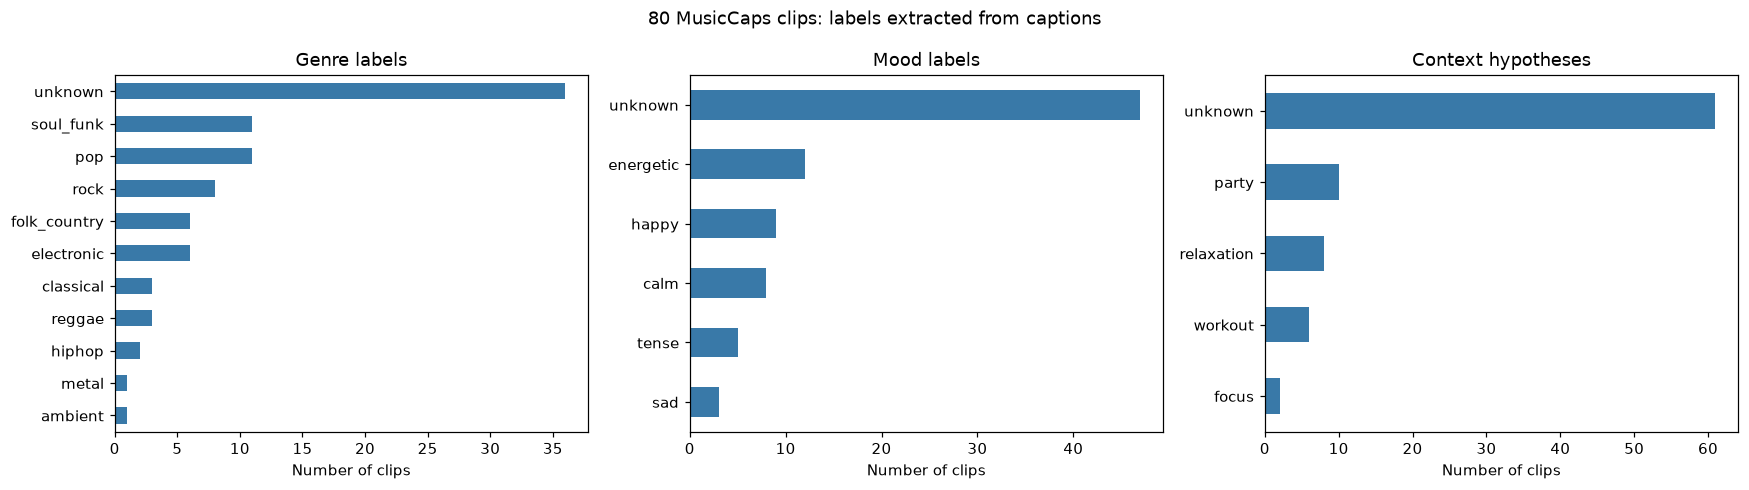

,feature,known_fraction
0,genres,0.5500
1,moods,0.4125
2,contexts,0.2375
3,tempo,0.3000
4,energy,0.3250
5,vocal,0.7500


energy,high,low,mixed_or_conflicting,unknown
tempo,,,,
fast,6,0,0,1
medium,0,0,0,8
slow,1,2,0,6
unknown,8,6,3,39


In [6]:
def counts_with_unknown(series):
    counts = Counter()
    for labels in series:
        counts.update(labels if labels else ['unknown'])
    return pd.Series(counts).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, column, title in zip(axes, ['genres','moods','contexts'], ['Genre labels','Mood labels','Context hypotheses']):
    counts_with_unknown(enriched[column]).plot.barh(ax=ax, color='#3979A8')
    ax.set_title(title); ax.set_xlabel('Number of clips'); ax.invert_yaxis()
fig.suptitle('80 MusicCaps clips: labels extracted from captions')
fig.tight_layout()
fig.savefig(RESULTS/'distributions.png', bbox_inches='tight')
plt.show()

coverage = pd.DataFrame({
    'feature': ['genres','moods','contexts','tempo','energy','vocal'],
    'known_fraction': [enriched[c].map(bool).mean() for c in ['genres','moods','contexts']] +
                      [enriched[c].ne('unknown').mean() for c in ['tempo','energy','vocal']]
})
display(coverage)
display(pd.crosstab(enriched.tempo, enriched.energy))

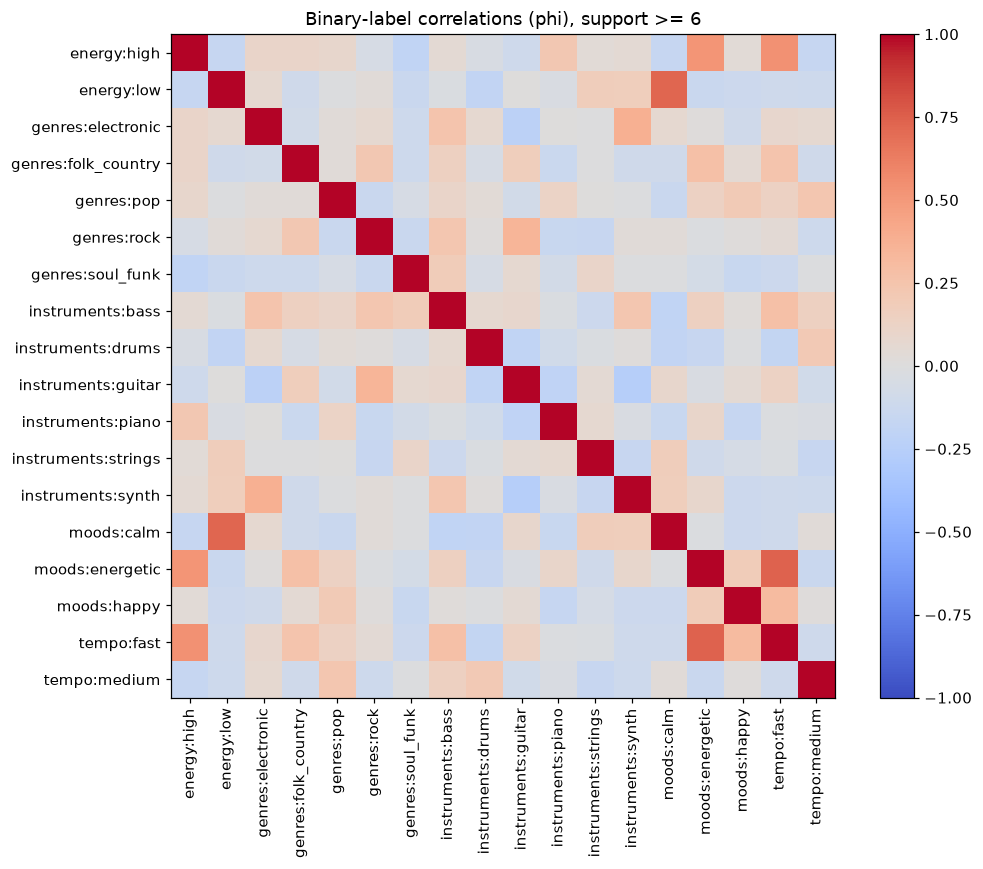

Context labels excluded: their correlation with mood/energy would be tautological by construction.


In [7]:
def feature_tokens(row, include_context=False):
    tokens = []
    for col in ['genres','moods','instruments']:
        tokens.extend(f'{col}:{value}' for value in row[col])
    for col in ['tempo','energy','vocal']:
        if row[col] not in {'unknown','mixed_or_conflicting'}:
            tokens.append(f'{col}:{row[col]}')
    if include_context:
        tokens.extend('contexts:'+x for x in row['contexts'])
    return tokens

semantic_vocab = sorted({token for _, row in enriched.iterrows() for token in feature_tokens(row)})
semantic_binary = np.array([[int(token in set(feature_tokens(row))) for token in semantic_vocab]
                            for _, row in enriched.iterrows()], dtype=float)
semantic_df = pd.DataFrame(semantic_binary, columns=semantic_vocab)
# Only variable and reasonably supported labels; phi = Pearson correlation for binary features.
selected = semantic_df.columns[(semantic_df.sum() >= 6) & (semantic_df.sum() <= len(enriched)-6)].tolist()[:18]
correlations = semantic_df[selected].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(selected)), selected, rotation=90)
ax.set_yticks(range(len(selected)), selected)
ax.set_title('Binary-label correlations (phi), support >= 6')
fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(RESULTS/'correlations.png', bbox_inches='tight'); plt.show()
print('Context labels excluded: their correlation with mood/energy would be tautological by construction.')

Корреляции описательные: их нельзя считать причинными связями или обобщать на музыкальный каталог. Выборка мала, признаки извлечены одним набором правил. Контексты намеренно исключены из корреляций и представления похожести: иначе повторно учитывались бы те же настроение и энергия.

## 5. Похожие треки и сравнение представлений

1. **TF-IDF:** слова и биграммы исходных caption, английские stop words, L2-нормализация.
2. **Semantic:** бинарные жанры, настроение, инструменты, темп, энергия и вокал, L2-нормализация. Unknown не становится общим «признаком похожести».
3. **Hybrid:** 0.7 × текстовая косинусная близость + 0.3 × семантическая. Вес выбран заранее, не оптимизируется по результатам. Для нулевого семантического вектора используется только TF-IDF.

Это похожесть **описаний**, которая может расходиться с воспринимаемой похожестью музыки. Фразы про качество записи тоже могут влиять на TF-IDF.

In [8]:
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1,2), min_df=1, max_df=0.95, sublinear_tf=True)
text_vectors = vectorizer.fit_transform(enriched.caption)
semantic_vectors = normalize(semantic_binary)
S_text = cosine_similarity(text_vectors)
S_semantic = cosine_similarity(semantic_vectors)
nonzero = semantic_binary.sum(axis=1) > 0
valid_pair = nonzero[:,None] & nonzero[None,:]
S_hybrid = np.where(valid_pair, 0.7*S_text + 0.3*S_semantic, S_text)
SIMILARITIES = {'tfidf': S_text, 'semantic': S_semantic, 'hybrid': S_hybrid}


def nearest(track_id, k=5, method='hybrid'):
    if track_id not in set(enriched.track_id):
        raise ValueError('Unknown track_id')
    if method not in SIMILARITIES:
        raise ValueError('Unknown representation')
    if not isinstance(k,int) or isinstance(k,bool) or not 1 <= k < len(enriched):
        raise ValueError('k must be between 1 and N-1')
    i = enriched.index[enriched.track_id.eq(track_id)][0]
    if method == 'semantic' and not nonzero[i]:
        return pd.DataFrame(columns=['track_id','score','audio_url'])
    scores = SIMILARITIES[method][i].copy()
    scores[i] = -np.inf
    # Stable order makes ties deterministic; zero overlap is not presented as evidence.
    order = [j for j in np.argsort(-scores, kind='stable') if j != i and scores[j] > 0][:k]
    result = enriched.iloc[order][['track_id','genres','moods','tempo','vocal','audio_url','caption']].copy()
    result.insert(1, 'score', np.round(scores[order],4))
    return result

example_ids = enriched.track_id.iloc[[0, len(enriched)//3, 2*len(enriched)//3]].tolist()
for track_id in example_ids:
    display(Markdown('### Пример: '+track_id))
    display(enriched.loc[enriched.track_id.eq(track_id), ['caption','genres','moods','audio_url']])
    display(nearest(track_id, k=3))

### Пример: 0fiOM---7QI

,caption,genres,moods,audio_url
0,"This is a traditional, cultural South Asian so...",[],"[energetic, happy]",https://www.youtube.com/watch?v=0fiOM---7QI&t=...


,track_id,score,genres,moods,tempo,vocal,audio_url,caption
3,40D4L5Ndi6k,0.2415,"[folk_country, pop]","[energetic, happy]",fast,vocal,https://www.youtube.com/watch?v=40D4L5Ndi6k&t=80s,A male vocalist sings this animated song in a ...
8,CP3phqztym0,0.2369,[pop],"[energetic, happy]",fast,vocal,https://www.youtube.com/watch?v=CP3phqztym0&t=30s,A male vocalist sings this vivacious latin pop...
23,RneRJ5ZnHlE,0.2330,[],[energetic],unknown,vocal,https://www.youtube.com/watch?v=RneRJ5ZnHlE&t=30s,This is a salsa song with an upbeat and vibran...


### Пример: UrgzGbGVV8I

,caption,genres,moods,audio_url
26,The song is an instrumental music piece. The s...,[],[],https://www.youtube.com/watch?v=UrgzGbGVV8I&t=30s


,track_id,score,genres,moods,tempo,vocal,audio_url,caption
60,rfQ94EXIpTc,0.2803,[],[calm],slow,instrumental,https://www.youtube.com/watch?v=rfQ94EXIpTc&t=30s,This music is a pleasant instrumental. The mus...
9,D2w3qHmJrdU,0.2509,[soul_funk],[],medium,instrumental,https://www.youtube.com/watch?v=D2w3qHmJrdU&t=0s,The song is an instrumental. The song is mediu...
36,cnvmLwFZr28,0.2184,[rock],[],slow,vocal,https://www.youtube.com/watch?v=cnvmLwFZr28&t=80s,This is a Korean indie rock piece. There is a ...


### Пример: ovVrS-q3Rzk

,caption,genres,moods,audio_url
53,This is a clip containing vinyl or deck scratc...,[hiphop],[calm],https://www.youtube.com/watch?v=ovVrS-q3Rzk&t=30s


,track_id,score,genres,moods,tempo,vocal,audio_url,caption
75,xb07gLlmkL8,0.1879,"[electronic, rock]",[calm],unknown,instrumental,https://www.youtube.com/watch?v=xb07gLlmkL8&t=30s,This music is instrumental. The tempo is mediu...
51,nvvXOfLs-ng,0.1724,[],[calm],unknown,unknown,https://www.youtube.com/watch?v=nvvXOfLs-ng&t=...,The low quality recording features an Enka son...
24,SG24NL2Xi3A,0.1685,[hiphop],[],unknown,vocal,https://www.youtube.com/watch?v=SG24NL2Xi3A&t=30s,The low quality recording features a hip hop s...


### Разбор соседей: где похожесть помогает, а где ошибается

- `0fiOM---7QI`: описание южноазиатской песни. Среди соседей встречается salsa. Общее энергичное настроение и инструменты могут быть полезны для запроса про активность, но не сохраняют культурный стиль. В словаре не хватает региональных жанров.
- `UrgzGbGVV8I`: инструментальный отрывок. Среди соседей есть другие инструментальные записи, но текстовые совпадения не гарантируют тот же тембр или мелодию. Добавление фильтра «без вокала» может быть полезнее простой смеси сходств.
- `ovVrS-q3Rzk`: hip-hop со скретчингом. Спокойное настроение и общие инструменты могут поднять запись с электронным/роковым описанием выше другого hip-hop. Это конкретный пример того, почему нельзя объявлять гибрид лучшей моделью без независимой оценки.

Эти наблюдения сделаны по исходным описаниям и выводу поиска, **не по прослушиванию**. Неполнота жанрового словаря особенно важна для неанглоязычных и региональных музыкальных традиций.

### Слабая диагностика: согласованность с `aspect_list`

Вспомогательные жанровые метки извлекаются из авторского списка аспектов. Для каждого запроса считаем, какая доля пяти предложенных соседей делит с ним хотя бы один такой жанр. Запросы без извлечённого жанра не учитываются; соседи без жанра считаются несовпавшими. Если соседей меньше пяти, недостающие считаются несовпавшими.

**Это не независимая разметка релевантности:** caption и aspect_list описывают один отрывок, возможны общие слова и авторские смещения; словарь тоже общий. Показатель пригоден только для диагностики жанровой согласованности. Нет пользовательских взаимодействий, музыкальных оценок или ground truth для настроения. Поэтому это не precision@5 рекомендательной системы и не доказательство, какой набор признаков лучше для пользователей.

In [9]:
def reference_genres(value):
    aspects = ast.literal_eval(value)
    if not isinstance(aspects,list):
        raise ValueError('aspect_list must be a list')
    return set(dictionary_labels(' . '.join(aspects), GENRES)[0])

reference = enriched.aspect_list.apply(reference_genres).tolist()
eval_ids = [i for i, labels in enumerate(reference) if labels]
rows = []
for method in SIMILARITIES:
    fractions = []
    for i in eval_ids:
        neighbors = nearest(enriched.track_id.iloc[i], 5, method)
        hits = sum(bool(reference[i] & reference[enriched.index[enriched.track_id.eq(tid)][0]])
                   for tid in neighbors.track_id)
        fractions.append(hits/5)
    rows.append({'representation':method, 'eligible_queries':len(eval_ids),
                 'weak_genre_agreement_at_5':float(np.mean(fractions)) if fractions else None})
comparison = pd.DataFrame(rows)
display(comparison)

sets_text = [set(nearest(t,5,'tfidf').track_id) for t in enriched.track_id]
sets_hybrid = [set(nearest(t,5,'hybrid').track_id) for t in enriched.track_id]
overlap = float(np.mean([len(a&b)/len(a|b) if a|b else 1 for a,b in zip(sets_text,sets_hybrid)]))
print('Mean Jaccard overlap of TF-IDF and hybrid top-5:', round(overlap,3))
print('This measures ranking change, not recommendation quality.')

,representation,eligible_queries,weak_genre_agreement_at_5
0,tfidf,49,0.244898
1,semantic,49,0.440816
2,hybrid,49,0.404082


Mean Jaccard overlap of TF-IDF and hybrid top-5: 0.313
This measures ranking change, not recommendation quality.


### t-SNE пространства текстовых представлений

t-SNE строится по полным TF-IDF-векторам с cosine distance. На 80 объектах достаточно `perplexity=15`. Координаты не используются в поиске соседей. Цвет показывает первую (алфавитно) извлечённую жанровую метку только для наглядности. Далёкие расстояния на двумерном графике не интерпретируются как точная музыкальная дистанция.

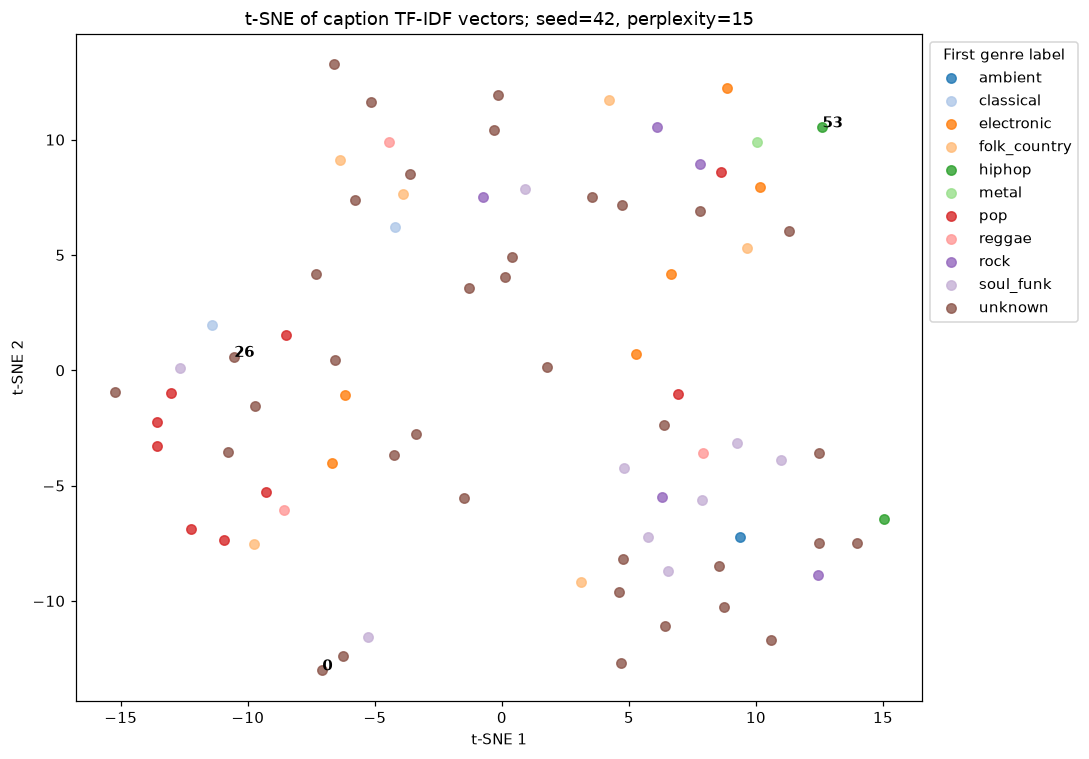

In [10]:
embedding_2d = TSNE(n_components=2, perplexity=15, metric='cosine', init='random',
                    random_state=SEED, learning_rate='auto', max_iter=1000).fit_transform(text_vectors.toarray())
labels = enriched.genres.apply(lambda x: x[0] if x else 'unknown')
fig, ax = plt.subplots(figsize=(10,7))
for color_index, label in enumerate(sorted(labels.unique())):
    mask = labels.eq(label).to_numpy()
    ax.scatter(embedding_2d[mask,0], embedding_2d[mask,1], label=label, alpha=0.8, s=38, color=plt.get_cmap('tab20')(color_index))
for idx in [0, len(enriched)//3, 2*len(enriched)//3]:
    ax.annotate(str(idx), embedding_2d[idx], fontsize=10, fontweight='bold')
ax.set_title('t-SNE of caption TF-IDF vectors; seed=42, perplexity=15')
ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
ax.legend(loc='upper left', bbox_to_anchor=(1,1), title='First genre label')
fig.tight_layout(); fig.savefig(RESULTS/'tsne.png', bbox_inches='tight'); plt.show()

### Фактические выводы этого запуска

Числа ниже вычисляются при выполнении; заранее не подставлены. Более высокое покрытие признака не доказывает его качество. Жанр и инструменты удобны для объяснимого похожего контента; настроение и темп ближе к пользовательским запросам, но нуждаются в проверке. Контексты потенциально полезны, однако наиболее рискованны из-за эвристического происхождения.

In [11]:
mood_known = int(enriched.moods.map(bool).sum())
genre_known = int(enriched.genres.map(bool).sum())
context_known = int(enriched.contexts.map(bool).sum())
conflicts = int(enriched.tempo.eq('mixed_or_conflicting').sum())
summary = {
    'n_clips':len(enriched), 'genre_coverage_n':genre_known, 'mood_coverage_n':mood_known,
    'context_hypotheses_n':context_known, 'tempo_conflicts_n':conflicts,
    'nonzero_semantic_vectors_n':int(nonzero.sum()),
    'tfidf_hybrid_neighbor_jaccard':overlap,
    'weak_comparison':comparison.to_dict('records'),
    'source_sha256':SOURCE_SHA256,
}
print(json.dumps(summary, ensure_ascii=False, indent=2))
display(Markdown(f"Из {len(enriched)} фрагментов жанровые свидетельства найдены у **{genre_known}**, "
                 f"настроение — у **{mood_known}**, гипотезы контекста — у **{context_known}**. "
                 f"Конфликтующих описаний темпа: **{conflicts}**. Остальные значения не угадываются."))

{
  "n_clips": 80,
  "genre_coverage_n": 44,
  "mood_coverage_n": 33,
  "context_hypotheses_n": 19,
  "tempo_conflicts_n": 0,
  "nonzero_semantic_vectors_n": 79,
  "tfidf_hybrid_neighbor_jaccard": 0.31269841269841264,
  "weak_comparison": [
    {
      "representation": "tfidf",
      "eligible_queries": 49,
      "weak_genre_agreement_at_5": 0.24489795918367346
    },
    {
      "representation": "semantic",
      "eligible_queries": 49,
      "weak_genre_agreement_at_5": 0.4408163265306122
    },
    {
      "representation": "hybrid",
      "eligible_queries": 49,
      "weak_genre_agreement_at_5": 0.40408163265306124
    }
  ],
  "source_sha256": "8cc109ac507b5e5aed8ea73a5c8f897a9d0793f7397427e000adf4c05f6021c7"
}


Из 80 фрагментов жанровые свидетельства найдены у **44**, настроение — у **33**, гипотезы контекста — у **19**. Конфликтующих описаний темпа: **0**. Остальные значения не угадываются.

## Ограничения и следующий эксперимент

- 80 десятисекундных отрывков не представляют полные треки, разнообразие исполнителей или предпочтения пользователей.
- Реальная музыкальная похожесть не оценивалась прослушиванием. Общие слова описаний могут создавать ложных соседей.
- Простые отрицания проверены, но сложная грамматика, сравнения и двусмысленные слова остаются источником ошибок. Энергия «loud» не равна измеренной громкости; «fast» не равняется BPM.
- Жанры и настроения не образуют полную таксономию. Отсутствие метки — пробел разметки, а не отрицательная метка.
- Контекст «для работы» нельзя надёжно установить только по медленному темпу и отсутствию вокала; он хранится как гипотеза, не как истина.
- Нет персонализации, пользовательских историй, модели онлайн-обучения и реального сравнения рекомендательного качества.
- Следующий эксперимент: вручную прослушать доступные отрывки, получить независимые оценки пар и пользовательских интентов, сравнить TF-IDF с CLAP/текстовыми эмбеддингами. Делить по исполнителям/источникам, фиксировать train/validation/test до настройки. Подбирать веса на validation, итоговые retrieval-метрики считать один раз на test. Не использовать признаки-цели как вход при проверке качества их предсказания.

**Что объяснить на защите:** откуда данные и права; почему это текстовый baseline; что означают unknown и context hypothesis; как TF-IDF и cosine формируют соседей; зачем t-SNE; почему согласованность с aspect_list не является музыкальной precision@5.

In [12]:
# Инварианты матриц и поиска; отдельная проверка без доступа к сети.
for name, matrix in SIMILARITIES.items():
    assert matrix.shape == (80,80)
    assert np.isfinite(matrix).all()
    assert np.allclose(matrix, matrix.T)
    assert matrix.min() >= -1e-7 and matrix.max() <= 1+1e-7
    for track_id in enriched.track_id:
        result = nearest(track_id, 5, name)
        assert track_id not in set(result.track_id)
        assert result.track_id.is_unique
check(nearest(example_ids[0]).equals(nearest(example_ids[0])))
for args in [('missing',5,'hybrid'), (example_ids[0],0,'hybrid'),
             (example_ids[0],80,'hybrid'), (example_ids[0],5,'missing')]:
    try:
        nearest(*args)
    except ValueError:
        checks += 1
    else:
        raise AssertionError('Invalid nearest-neighbor input accepted')
assert enriched[['title','artist']].isna().all().all()
print('All dataset, extraction, matrix and retrieval checks passed.')

# Portable export: lists and evidence become valid JSON inside CSV cells.
export = enriched.copy()
for col in ['genres','moods','instruments','contexts','evidence']:
    export[col] = export[col].apply(lambda x: json.dumps(x, ensure_ascii=False))
export.to_csv(RESULTS/'musiccaps_80_enriched.csv', index=False)
coverage.to_csv(RESULTS/'feature_coverage.csv', index=False)
comparison.to_csv(RESULTS/'representation_comparison.csv', index=False)
(RESULTS/'metrics.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print('Exported:', sorted(p.name for p in RESULTS.iterdir()))

All dataset, extraction, matrix and retrieval checks passed.
Exported: ['correlations.png', 'distributions.png', 'feature_coverage.csv', 'metrics.json', 'musiccaps_80_enriched.csv', 'representation_comparison.csv', 'tsne.png']
